## Dataset + wizualizacja

In [ ]:
import random
random.seed(42)

n = 100
x = [i for i in range(1, n)]
y = [2 * xi + random.uniform(-10, 10) * 2 for xi in x] # y = 2x + noise

print("Generated x values:", x)
print("Generated y values:", y)

Generated x values: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
Generated y values: [7.577071938315349, -14.999569791093322, -2.9988272652352297, -3.071570474047089, 19.458848566560498, 19.06797949691645, 29.687182708193816, -0.5224466948233548, 14.876872787410818, 1.1918887775228129, 10.745518992144135, 24.214211524134495, 7.061438787354547, 15.95350602746594, 35.995377511180926, 33.797659224128665, 22.817624881627868, 39.57062735503635, 50.377218267113065, 20.25995038712244, 54.23277007331232, 51.92557579952907, 39.61002066071968, 34.21917999247126, 68.28852288827125, 45.463781804505075, 37.70983373520592, 39.86865507333856, 71.89977465389839, 64

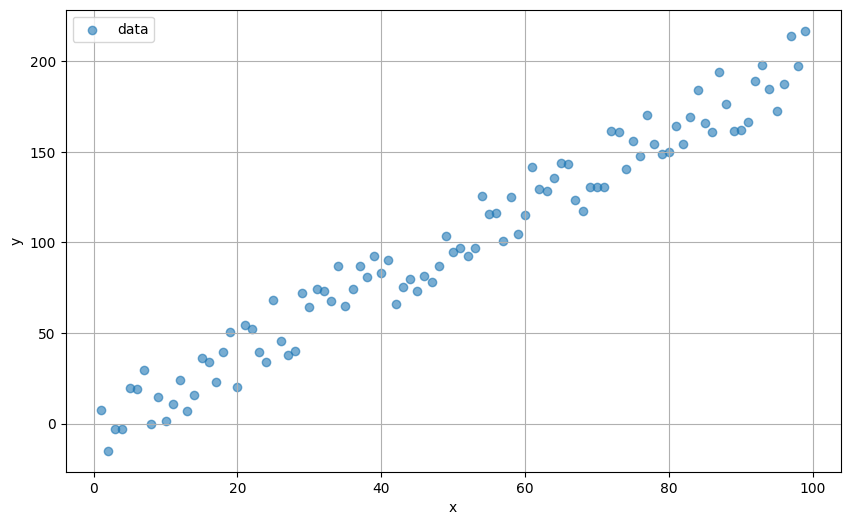

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='data', alpha=0.6)
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.grid(True)
plt.show()

Dla:

- jednej zmiennej objaśniającej $x$ przyjmującej wartości $x_1, ..., x_n$
- jednej zmiennej objaśnianej $y$ przyjmującej wartości $y_1, ..., y_n$

wartości parametrów $\beta_0, \beta_1$ minimalizujące RSS są zadane następująco:

$\hat{\beta}_1 = \frac{\sum_{i=1}^n (x_i - \overline{x})(y_i - \overline{y})}{\sum_{i=1}^n (x_i - \overline{x})^2}$

$\hat{\beta}_0 = \overline{y} - \hat{\beta}_1 \overline{x}$

Dopasuj model liniowy do wygenerowanych wcześniej danych

a) w czystym Pythonie (pętle dozwolone)

b) w NumPy (pętle niedozwolone)

### 1. Czysty Python

In [ ]:
# Beta_1 (slope)

beta_1 = ...

# Beta_0 (intercept)

beta_0 = ...


print(f"Estimated beta_1 (slope): {beta_1:.4f}")
print(f"Estimated beta_0 (intercept): {beta_0:.4f}")

Pure Python - Estimated beta_1 (slope): 2.0361
Pure Python - Estimated beta_0 (intercept): -2.7768


### 2. NumPy

Operacje w NumPy są **zwektoryzowane**. Oznacza to mniej więcej tyle:

1) tablica pythonowych obiektów jest przepisywana do tablicy odpowiedniego typu (z języka C), np. uint32_t - optymalizujemy zużycie pamięci
2) zamiast odwoływać się do konkretnych elementów tablicy, wykonujemy działania na całych wektorach.

Przydatne operacje:

- x_np = np.array(x) - przepisuje tablicę x do obiektu NumPy
- x_mean = np.mean(x_np) - liczy średnią po wartościach z x_np
- s = np.sum(x_np) - liczy sumę elementów tablicy x_np

Wygodne operacje na tablicach:

```
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

sum_vector = a + b
print(sum_vector)
# [5 7 9]

dot_product = np.dot(a, b)
print(dot_product)
# 32
```

In [ ]:
import numpy as np


# Beta_1 (slope)

beta_1 = ...

# Beta_0 (intercept)

beta_0 = ...


print(f"Estimated beta_1 (slope): {beta_1:.4f}")
print(f"Estimated beta_0 (intercept): {beta_0:.4f}")

NumPy - Estimated beta_1 (slope): 2.0361
NumPy - Estimated beta_0 (intercept): -2.7768


### Wizualizacja

In [ ]:
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider
from IPython.display import display
import numpy as np

x_plot = np.array(x)
y_plot = np.array(y)

def calculate_sse(y_true, y_pred):
    return np.sum((y_true - y_pred)**2)

def plot_regression(beta_0, beta_1):
    plt.figure(figsize=(10, 6))
    plt.scatter(x_plot, y_plot, label='Original data', color='blue')

    y_pred_adjusted = beta_0 + beta_1 * x_plot
    sse_adjusted = calculate_sse(y_plot, y_pred_adjusted)
    plt.plot(x_plot, y_pred_adjusted, color='red', linestyle='--', label=f'Current line: y = {beta_1:.2f}x + {beta_0:.2f} (RSS={sse_adjusted:.2f})')

    y_pred_best = beta_0_numpy + beta_1_numpy * x_plot
    sse_best = calculate_sse(y_plot, y_pred_best)
    plt.plot(x_plot, y_pred_best, color='green', linestyle='-', linewidth=2, label=f'Best fit line: y = {beta_1_numpy:.2f}x + {beta_0_numpy:.2f} (RSS={sse_best:.2f})')

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Best fit RSS: {:.2f} | Current RSS: {:.2f}'.format(sse_best, sse_adjusted))
    plt.legend()
    plt.grid(True)
    plt.show()

beta_0_slider = FloatSlider(min=beta_0_numpy - 50, max=beta_0_numpy + 50, step=0.5, value=beta_0_numpy, description='beta_0')
beta_1_slider = FloatSlider(min=beta_1_numpy - 5, max=beta_1_numpy + 5, step=0.1, value=beta_1_numpy, description='beta_1')
interact(plot_regression, beta_0=beta_0_slider, beta_1=beta_1_slider);

interactive(children=(FloatSlider(value=-2.776774019351052, description='beta_0', max=47.22322598064895, min=-…